# Heart Sound Classification (CNN on 3-channel spectrograms)

**Task:** classify heart sound recordings (CirCor dataset, PhysioNet) as *Normal* or *Abnormal*.

**Evaluation design (leak-free):**
- **Patient-level splits.** Each patient has several recordings (e.g. `68363_AV`, `68363_MV`). All recordings of a patient stay on the same side of every split (`StratifiedGroupKFold`), so the model is never tested on a heart it has already heard.
- **Training-only augmentation.** Augmented copies of abnormal recordings are added to the **training data only**. Validation and test sets contain only original, unaltered recordings.
- **Separate early-stopping set.** Early stopping uses a validation split carved from the training patients, never the test patients.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Imports**

In [2]:
import os
import glob
import re
import random
import librosa
import librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_recall_fscore_support)
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
# Make results repeatable (seeds Python's random, NumPy and TensorFlow)
SEED = 42
tf.keras.utils.set_random_seed(SEED)

## **Dataset**

In [4]:
DATASET_PATH = "/content/drive/MyDrive/training_data"

## **Generate Metadata**

In [5]:
txt_files = glob.glob(os.path.join(DATASET_PATH, "*.txt"))
metadata_list = []

for txt_file in txt_files:
    try:
        with open(txt_file, "r") as f:
            lines = f.readlines()

        outcome = None
        wav_files = []
        for line in lines:
            line = line.strip()
            if line.lower().startswith("#outcome:"):
                m = re.search(r"#Outcome:\s*(\w+)", line, re.IGNORECASE)
                if m:
                    outcome = m.group(1).capitalize()
            if ".wav" in line.lower():
                for part in line.split():
                    if part.lower().endswith(".wav") and os.path.exists(os.path.join(DATASET_PATH, part)):
                        wav_files.append(part)

        if outcome in ["Normal", "Abnormal"]:
            for wav in wav_files:
                metadata_list.append({"filename": wav, "label": outcome})
    except Exception as e:
        print(f"Error processing {txt_file}: {e}")

metadata = pd.DataFrame(metadata_list).drop_duplicates("filename").reset_index(drop=True)
metadata["patient_id"] = metadata["filename"].str.split("_").str[0]   # e.g. 68363_AV.wav -> 68363

print("Labeled recordings:", len(metadata), "| patients:", metadata["patient_id"].nunique())
print(metadata["label"].value_counts())
metadata.head()

Labeled recordings: 2633 | patients: 779
label
Normal      1410
Abnormal    1223
Name: count, dtype: int64


,filename,label,patient_id
0,68363_AV.wav,Abnormal,68363
1,68363_MV.wav,Abnormal,68363
2,50743_AV_1.wav,Normal,50743
3,50743_AV_2.wav,Normal,50743
4,50743_AV_3.wav,Normal,50743


## **Audio Loading, Augmentation and 3-Channel Spectrograms**

In [6]:
MAX_LEN = 5      # seconds
N_MELS = 128
N_FRAMES = 128

def fix_length(signal, sr, max_len=MAX_LEN):
    """Trim or zero-pad a signal to exactly max_len seconds."""
    target = int(sr * max_len)
    signal = signal[:target]
    if len(signal) < target:
        signal = np.pad(signal, (0, target - len(signal)))
    return signal

def load_signal(file_path):
    signal, sr = librosa.load(file_path, sr=None)
    return fix_length(signal, sr), sr

def augment_audio(signal, sr):
    """Random time-stretch, pitch-shift and light noise. Used on TRAINING data only."""
    if random.random() < 0.5:
        signal = librosa.effects.time_stretch(signal, rate=random.uniform(0.8, 1.2))
    if random.random() < 0.5:
        signal = librosa.effects.pitch_shift(signal, sr=sr, n_steps=random.randint(-2, 2))
    if random.random() < 0.5:
        noise_amp = 0.005 * np.random.uniform() * np.amax(np.abs(signal))
        signal = signal + noise_amp * np.random.normal(size=signal.shape)
    return fix_length(signal, sr)

def to_spectrogram_3ch(signal, sr):
    """Log-Mel spectrogram + delta + delta-delta, shaped (128, 128, 3)."""
    mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=N_MELS)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    delta = librosa.feature.delta(mel_db)
    delta2 = librosa.feature.delta(mel_db, order=2)
    combined = np.stack([mel_db, delta, delta2], axis=-1)
    if combined.shape[1] < N_FRAMES:
        combined = np.pad(combined, ((0, 0), (0, N_FRAMES - combined.shape[1]), (0, 0)))
    return combined[:, :N_FRAMES, :].astype(np.float32)

## **Extract Features (original recordings only, no augmentation)**

In [7]:
label_map = {"Normal": 0, "Abnormal": 1}
signals, srs, X_list, y_list, group_list = [], [], [], [], []

for _, row in metadata.iterrows():
    try:
        signal, sr = load_signal(os.path.join(DATASET_PATH, row["filename"]))
    except Exception as e:
        print(f"Error processing {row['filename']}: {e}")
        continue
    signals.append(signal)
    srs.append(sr)
    X_list.append(to_spectrogram_3ch(signal, sr))
    y_list.append(label_map[row["label"]])
    group_list.append(row["patient_id"])

X = np.array(X_list)
labels = np.array(y_list)
groups = np.array(group_list)
print("Feature shape:", X.shape)            # (N, 128, 128, 3)
print("Normal / Abnormal:", np.bincount(labels))

Feature shape: (2633, 128, 128, 3)
Normal / Abnormal: [1410 1223]


## **Model and Leak-Free Training Helpers**

In [8]:
def build_model():
    model = models.Sequential([
        layers.Input(shape=(128, 128, 3)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


def make_training_set(idx):
    """Original training recordings + one augmented copy of each abnormal one."""
    abnormal_idx = idx[labels[idx] == 1]
    X_aug = np.array([to_spectrogram_3ch(augment_audio(signals[i].copy(), srs[i]), srs[i])
                      for i in abnormal_idx])
    X_tr = np.concatenate([X[idx], X_aug])
    y_tr = np.concatenate([labels[idx], np.ones(len(abnormal_idx), dtype=int)])
    order = np.random.permutation(len(y_tr))
    return X_tr[order], y_tr[order]


def split_by_patient(idx, n_splits=5, seed=SEED):
    """Hold out about 1/n_splits of the patients in idx (stratified by label)."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    inner_tr, inner_va = next(sgkf.split(X[idx], labels[idx], groups[idx]))
    return idx[inner_tr], idx[inner_va]


def fit_and_evaluate(train_idx, test_idx, max_epochs=30, verbose=0):
    """Train on train_idx patients (augmented), early-stop on a separate set of
    training patients, and evaluate on untouched test_idx recordings."""
    fit_idx, es_idx = split_by_patient(train_idx)
    X_fit, y_fit = make_training_set(fit_idx)

    weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_fit)
    class_weight = {0: weights[0], 1: weights[1]}

    model = build_model()
    history = model.fit(
        X_fit, y_fit,
        epochs=max_epochs,
        batch_size=32,
        validation_data=(X[es_idx], labels[es_idx]),
        callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
        class_weight=class_weight,
        verbose=verbose,
    )

    y_true = labels[test_idx]
    y_pred = (model.predict(X[test_idx], verbose=0) > 0.5).astype(int).ravel()
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[1], zero_division=0)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "precision": p[0], "recall": r[0], "f1": f1[0]}
    return model, history, y_true, y_pred, metrics

## **5-Fold Patient-Level Cross-Validation**

In [9]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
all_idx = np.arange(len(labels))
fold_results = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, labels, groups), start=1):
    assert not set(groups[train_idx]) & set(groups[test_idx])     # no patient in both sets
    _, _, _, _, m = fit_and_evaluate(train_idx, test_idx)
    fold_results.append(m)
    print(f"Fold {fold}: accuracy {m['accuracy']:.4f} | abnormal precision {m['precision']:.4f} "
          f"| recall {m['recall']:.4f} | F1 {m['f1']:.4f}  (test recordings: {len(test_idx)})")

cv_df = pd.DataFrame(fold_results)
print("\nCross-validation (5-fold, patient-level), mean ± std:")
for col in ["accuracy", "precision", "recall", "f1"]:
    print(f"  {col:9s}: {cv_df[col].mean():.4f} ± {cv_df[col].std():.4f}")

Fold 1: accuracy 0.4792 | abnormal precision 0.4615 | recall 0.9000 | F1 0.6102  (test recordings: 530)
Fold 2: accuracy 0.4623 | abnormal precision 0.4602 | recall 0.8851 | F1 0.6055  (test recordings: 504)
Fold 3: accuracy 0.5576 | abnormal precision 0.0000 | recall 0.0000 | F1 0.0000  (test recordings: 538)
Fold 4: accuracy 0.4895 | abnormal precision 0.4987 | recall 0.7154 | F1 0.5877  (test recordings: 525)
Fold 5: accuracy 0.5354 | abnormal precision 0.0000 | recall 0.0000 | F1 0.0000  (test recordings: 536)

Cross-validation (5-fold, patient-level), mean ± std:
  accuracy : 0.5048 ± 0.0401
  precision: 0.2841 ± 0.2598
  recall   : 0.5001 ± 0.4622
  f1       : 0.3607 ± 0.3294


## **Hold-Out Test Set (20% of patients)**

In [10]:
train_idx, test_idx = split_by_patient(all_idx, n_splits=5, seed=SEED + 1)
assert not set(groups[train_idx]) & set(groups[test_idx])
print("Train recordings:", len(train_idx), "| Test recordings:", len(test_idx))
print("Train patients:", len(set(groups[train_idx])), "| Test patients:", len(set(groups[test_idx])))
print("Test Normal / Abnormal:", np.bincount(labels[test_idx]))

Train recordings: 2118 | Test recordings: 515
Train patients: 623 | Test patients: 156
Test Normal / Abnormal: [278 237]


## **Build CNN Model**

In [11]:
build_model().summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

## **Train Final Model (EarlyStopping + Class Weights, training patients only)**

In [12]:
model, history, y_true, y_pred, test_metrics = fit_and_evaluate(train_idx, test_idx, max_epochs=100, verbose=1)
print("Test metrics:", {k: round(float(v), 4) for k, v in test_metrics.items()})

Epoch 1/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 26s 211ms/step - accuracy: 0.5156 - loss: 0.6738 - val_accuracy: 0.5940 - val_loss: 0.7296
Epoch 2/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.5460 - loss: 0.6478 - val_accuracy: 0.4176 - val_loss: 0.7490
Epoch 3/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.5444 - loss: 0.6402 - val_accuracy: 0.4060 - val_loss: 1.7035
Epoch 4/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.5697 - loss: 0.6238 - val_accuracy: 0.4060 - val_loss: 3.3200
Epoch 5/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.5921 - loss: 0.6060 - val_accuracy: 0.4060 - val_loss: 2.8494
Epoch 6/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.5969 - loss: 0.5965 - val_accuracy: 0.4942 - val_loss: 0.7629
Test metrics: {'accuracy': 0.5398, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


## **Plot Accuracy**

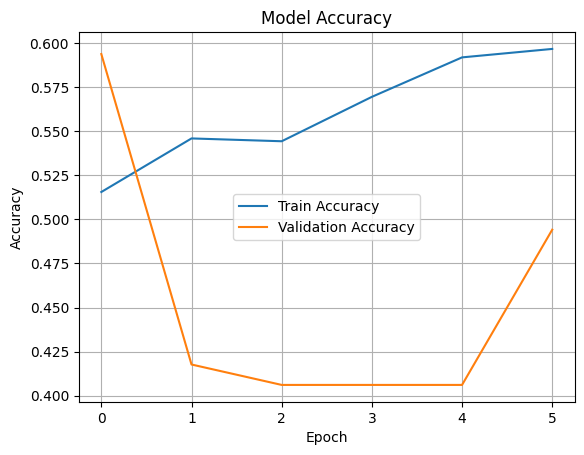

In [13]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

## **Evaluate on the Hold-Out Test Set: Confusion Matrix & Report**

Classification report (hold-out test patients):
              precision    recall  f1-score   support

      Normal       0.54      1.00      0.70       278
    Abnormal       0.00      0.00      0.00       237

    accuracy                           0.54       515
   macro avg       0.27      0.50      0.35       515
weighted avg       0.29      0.54      0.38       515



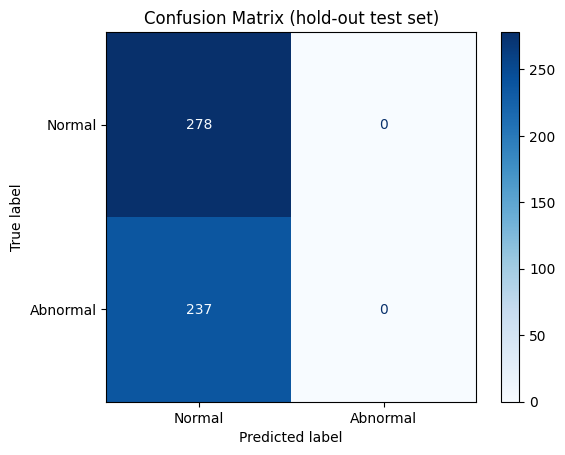

In [14]:
print("Classification report (hold-out test patients):")
print(classification_report(y_true, y_pred, target_names=["Normal", "Abnormal"], zero_division=0))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Abnormal"]).plot(cmap="Blues")
plt.title("Confusion Matrix (hold-out test set)")
plt.show()

## **Visualize Sample Heart Sound & MFCC**

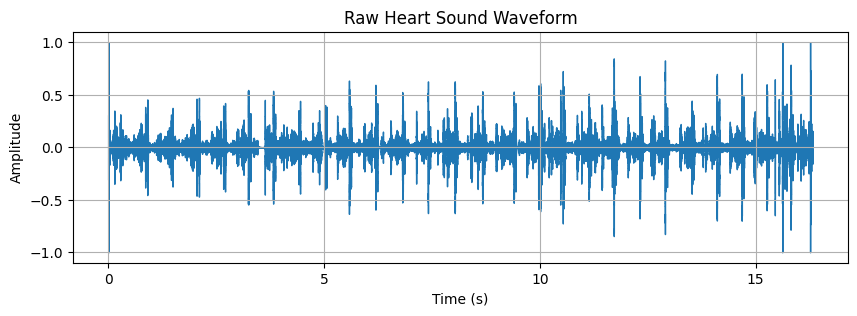

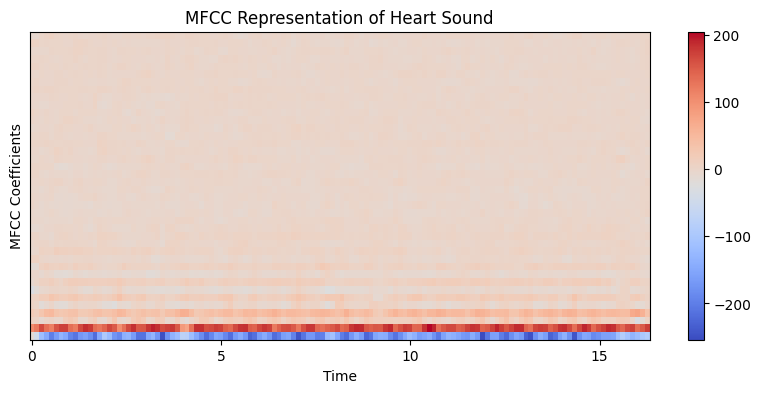

In [15]:
import librosa.display

# Use any file for demonstration
demo_file = os.path.join(DATASET_PATH, metadata.iloc[0]["filename"])
signal, sr = librosa.load(demo_file, sr=None)

# Waveform
plt.figure(figsize=(10, 3))
librosa.display.waveshow(signal, sr=sr)
plt.title("Raw Heart Sound Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

# MFCC
mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=40)
plt.figure(figsize=(10, 4))
librosa.display.specshow(mfcc, x_axis='time', sr=sr)
plt.colorbar()
plt.title("MFCC Representation of Heart Sound")
plt.xlabel("Time")
plt.ylabel("MFCC Coefficients")
plt.show()

## **Exploratory Data Analysis**

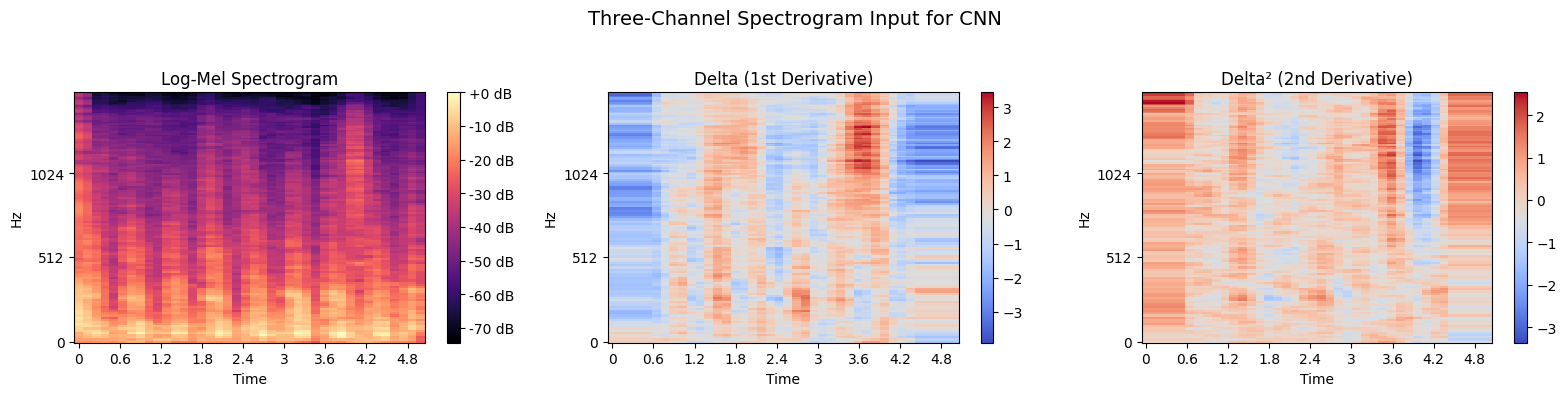

In [16]:
sample_file = os.path.join(DATASET_PATH, "68363_AV.wav")

# Load audio
sig, sr = librosa.load(sample_file, sr=None)
sig = sig[:sr * 5]
if len(sig) < sr * 5:
    sig = np.pad(sig, (0, sr * 5 - len(sig)))

# Compute log-mel spectrogram
mel = librosa.feature.melspectrogram(y=sig, sr=sr, n_mels=128)
mel_db = librosa.power_to_db(mel, ref=np.max)

# Compute delta and delta²
delta = librosa.feature.delta(mel_db)
delta2 = librosa.feature.delta(mel_db, order=2)

# Plot all three
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
librosa.display.specshow(mel_db, x_axis='time', y_axis='mel', sr=sr)
plt.title('Log-Mel Spectrogram')
plt.colorbar(format='%+2.0f dB')

plt.subplot(1, 3, 2)
librosa.display.specshow(delta, x_axis='time', y_axis='mel', sr=sr)
plt.title('Delta (1st Derivative)')
plt.colorbar()

plt.subplot(1, 3, 3)
librosa.display.specshow(delta2, x_axis='time', y_axis='mel', sr=sr)
plt.title('Delta² (2nd Derivative)')
plt.colorbar()

plt.suptitle('Three-Channel Spectrogram Input for CNN', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()